# FoodWise — Exploratory Data Analysis (EDA)
This notebook performs comprehensive exploratory analysis on the raw Zomato multi-city restaurant dataset in India.

### Key Objectives:
1. Inspect row/column dimensions, datatypes, and missing values.
2. Examine distributions of ratings, prices, and delivery times.
3. Analyze restaurant concentration across Indian cities.
4. Uncover the most popular cuisines and dishes.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

DATA_PATH = Path("../data/raw/zomato_dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../zomato_dataset.csv")

df = pd.read_csv(DATA_PATH)
print("Dataset Loaded Successfully!")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
df.head()

Dataset Loaded Successfully!
Total Rows: 44,891
Total Columns: 7


,Restaurant Name,Rating,Cuisine,Average Price,Average Delivery Time,Safety Measure,Location
0,Campus Bakers,4.3,"Bakery, Fast Food, Pizza, Sandwich, Burger",₹50 for one,36 min,Restaurant partner follows WHO protocol,Agra
1,Mama Chicken Mama Franky House,4,"North Indian, Mughlai, Rolls, Burger, Momos",₹50 for one,22 min,Follows all Max Safety measures to ensure your...,Agra
2,GMB - Gopika Sweets & Restaurant,4.2,"North Indian, South Indian, Chinese, Fast Food...",₹50 for one,27 min,Follows all Max Safety measures to ensure your...,Agra
3,Shree Bankey Bihari Misthan Bhandar,4.2,"Mithai, Street Food, South Indian, Chinese, Ic...",₹50 for one,28 min,Restaurant partner follows WHO protocol,Agra
4,Burger King,4.2,"Burger, Fast Food, Beverages",₹50 for one,26 min,Follows all Max Safety measures to ensure your...,Agra


## 1. Dataset Schema & Missing Values

In [2]:
print("--- Column Data Types & Non-Null Counts ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print(f"\nExact Duplicate Rows: {df.duplicated().sum()}")

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 44891 entries, 0 to 44890
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Restaurant Name        44891 non-null  str  
 1   Rating                 44891 non-null  str  
 2   Cuisine                44872 non-null  str  
 3   Average Price          44891 non-null  str  
 4   Average Delivery Time  44891 non-null  str  
 5   Safety Measure         44891 non-null  str  
 6   Location               44891 non-null  str  
dtypes: str(7)
memory usage: 8.1 MB

--- Missing Values Count ---
Restaurant Name           0
Rating                    0
Cuisine                  19
Average Price             0
Average Delivery Time     0
Safety Measure            0
Location                  0
dtype: int64

Exact Duplicate Rows: 140


## 2. City Distribution Analysis
Let us examine the top 15 cities with the highest number of restaurant listings.

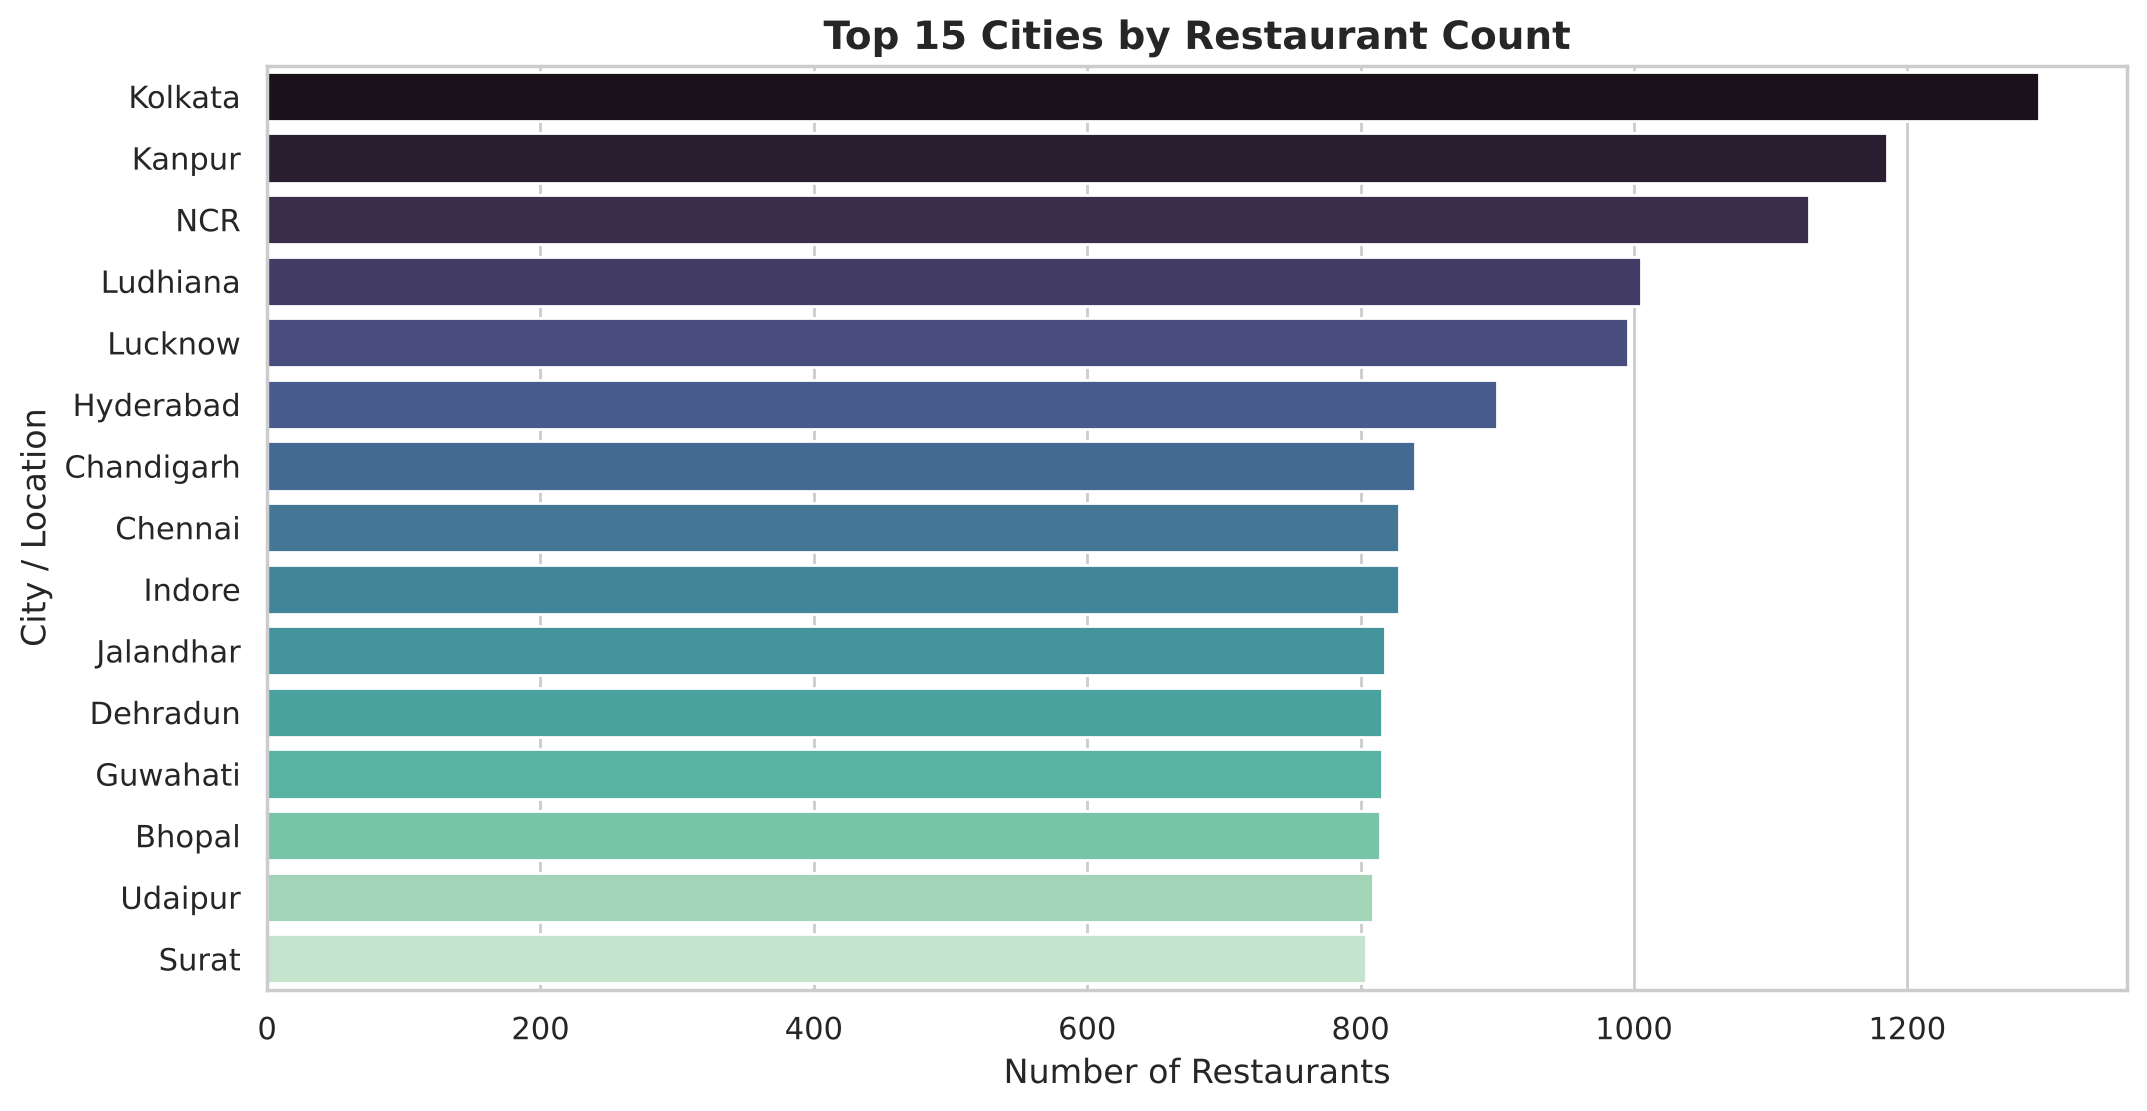

In [3]:
top_cities = df["Location"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_cities.values, y=top_cities.index, hue=top_cities.index, palette="mako", legend=False)
plt.title("Top 15 Cities by Restaurant Count", fontsize=14, weight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("City / Location")
plt.show()

## 3. Rating Distribution
The `Rating` column contains numeric ratings as well as '-' (unrated) and 'New' (newly opened).
Let's convert ratings to numeric floats and analyze the distribution.

Rating Summary Statistics:
count    37826.000000
mean         3.922495
std          0.346783
min          2.400000
25%          3.700000
50%          4.000000
75%          4.200000
max          4.900000
Name: Rating, dtype: float64


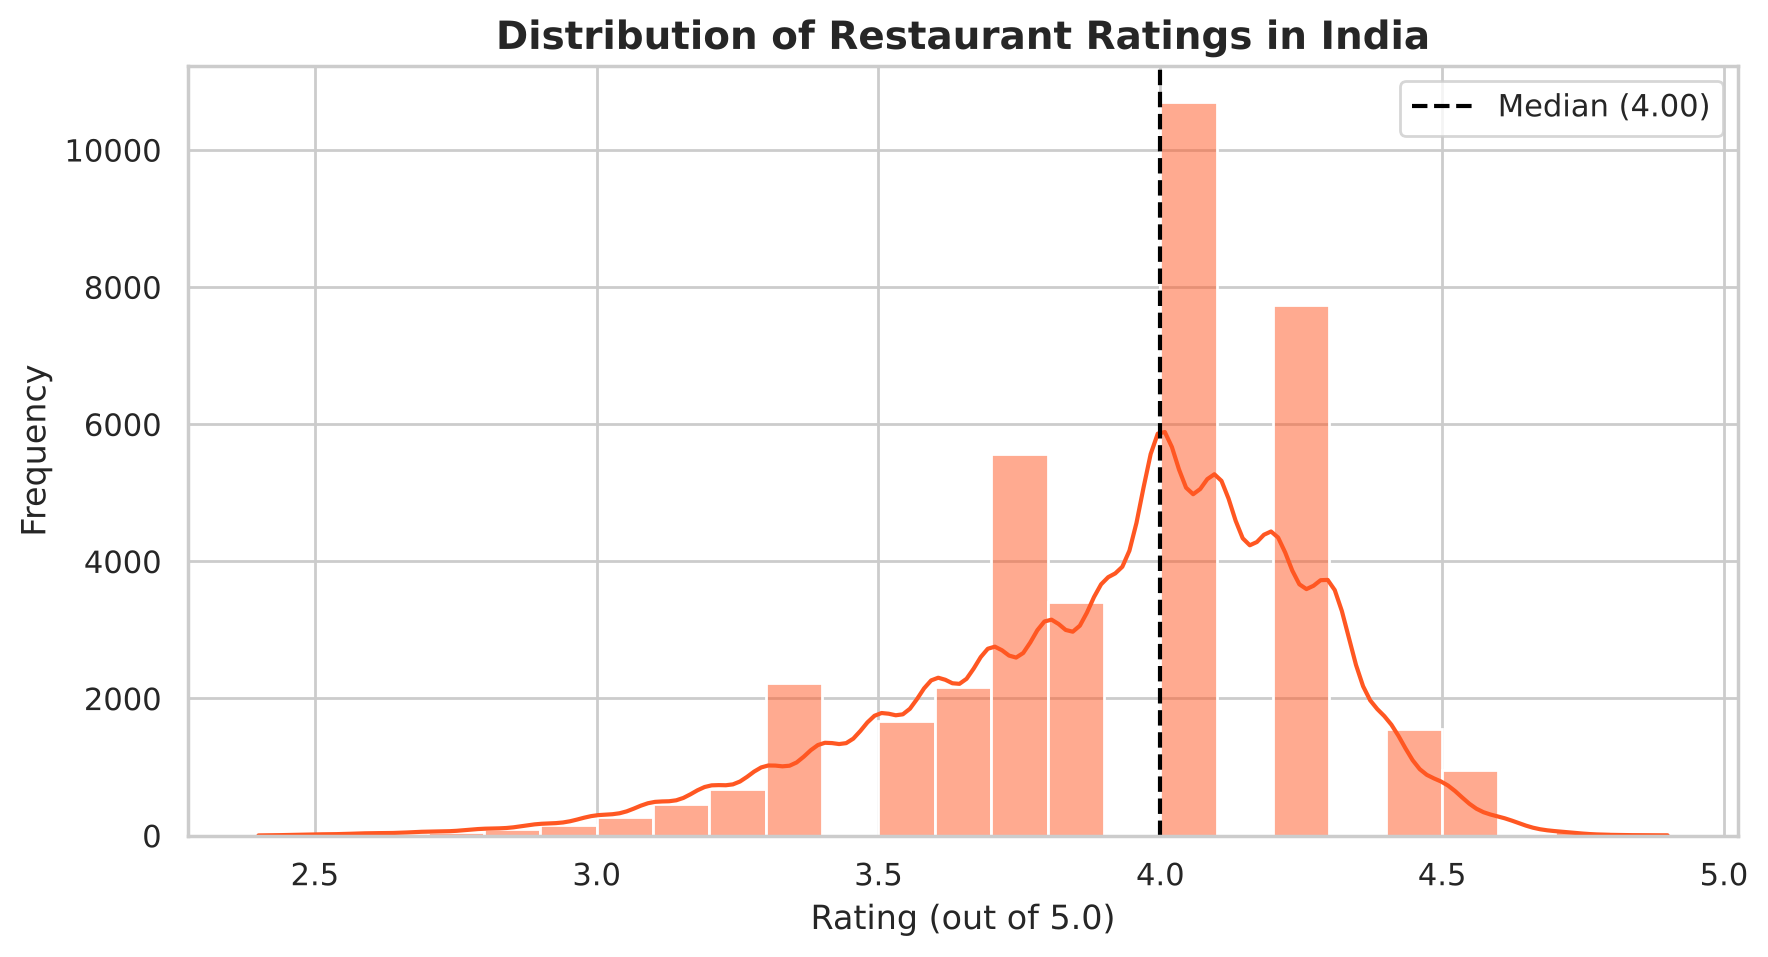

In [4]:
# Convert ratings to float, ignoring non-numeric strings
ratings_numeric = pd.to_numeric(df["Rating"].replace({"-": np.nan, "New": np.nan}), errors="coerce")

print("Rating Summary Statistics:")
print(ratings_numeric.describe())

plt.figure(figsize=(10, 5))
sns.histplot(ratings_numeric.dropna(), bins=25, kde=True, color="#ff5722")
plt.axvline(ratings_numeric.median(), color="black", linestyle="--", label=f"Median ({ratings_numeric.median():.2f})")
plt.title("Distribution of Restaurant Ratings in India", fontsize=14, weight="bold")
plt.xlabel("Rating (out of 5.0)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

## 4. Price & Cost Analysis
Extract numeric cost for one in ₹ and visualize distribution across budget segments.

Price Summary Statistics (₹ for one):
count    44868.000000
mean       173.260542
std         92.784485
min         10.000000
25%        100.000000
50%        150.000000
75%        200.000000
max       2000.000000
Name: Average Price, dtype: float64


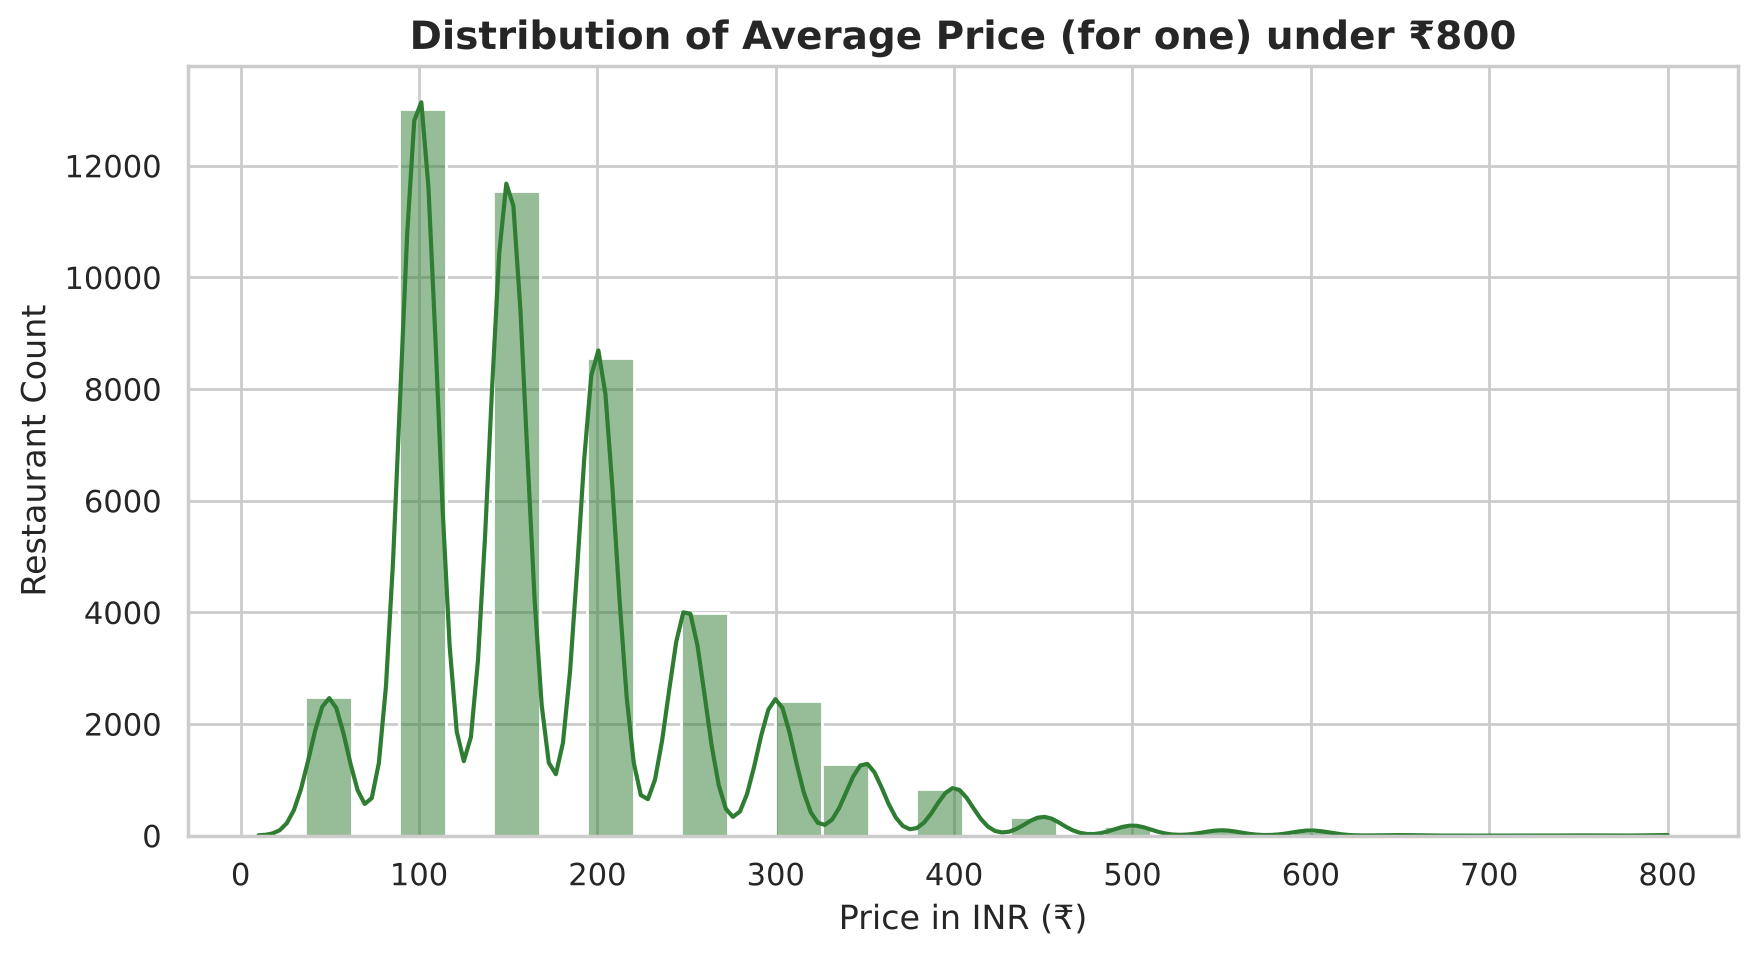

In [5]:
import re

def extract_price(v):
    if pd.isna(v): return np.nan
    clean = str(v).replace(",", "").replace("₹", "")
    m = re.search(r"(\d+)", clean)
    return float(m.group(1)) if m else np.nan

prices = df["Average Price"].apply(extract_price).dropna()

print("Price Summary Statistics (₹ for one):")
print(prices.describe())

plt.figure(figsize=(10, 5))
sns.histplot(prices[prices <= 800], bins=30, kde=True, color="#2e7d32")
plt.title("Distribution of Average Price (for one) under ₹800", fontsize=14, weight="bold")
plt.xlabel("Price in INR (₹)")
plt.ylabel("Restaurant Count")
plt.show()

## 5. Most Popular Cuisines & Food Items
Restaurants list multiple cuisines separated by commas. We unnest individual cuisines to identify the most common.

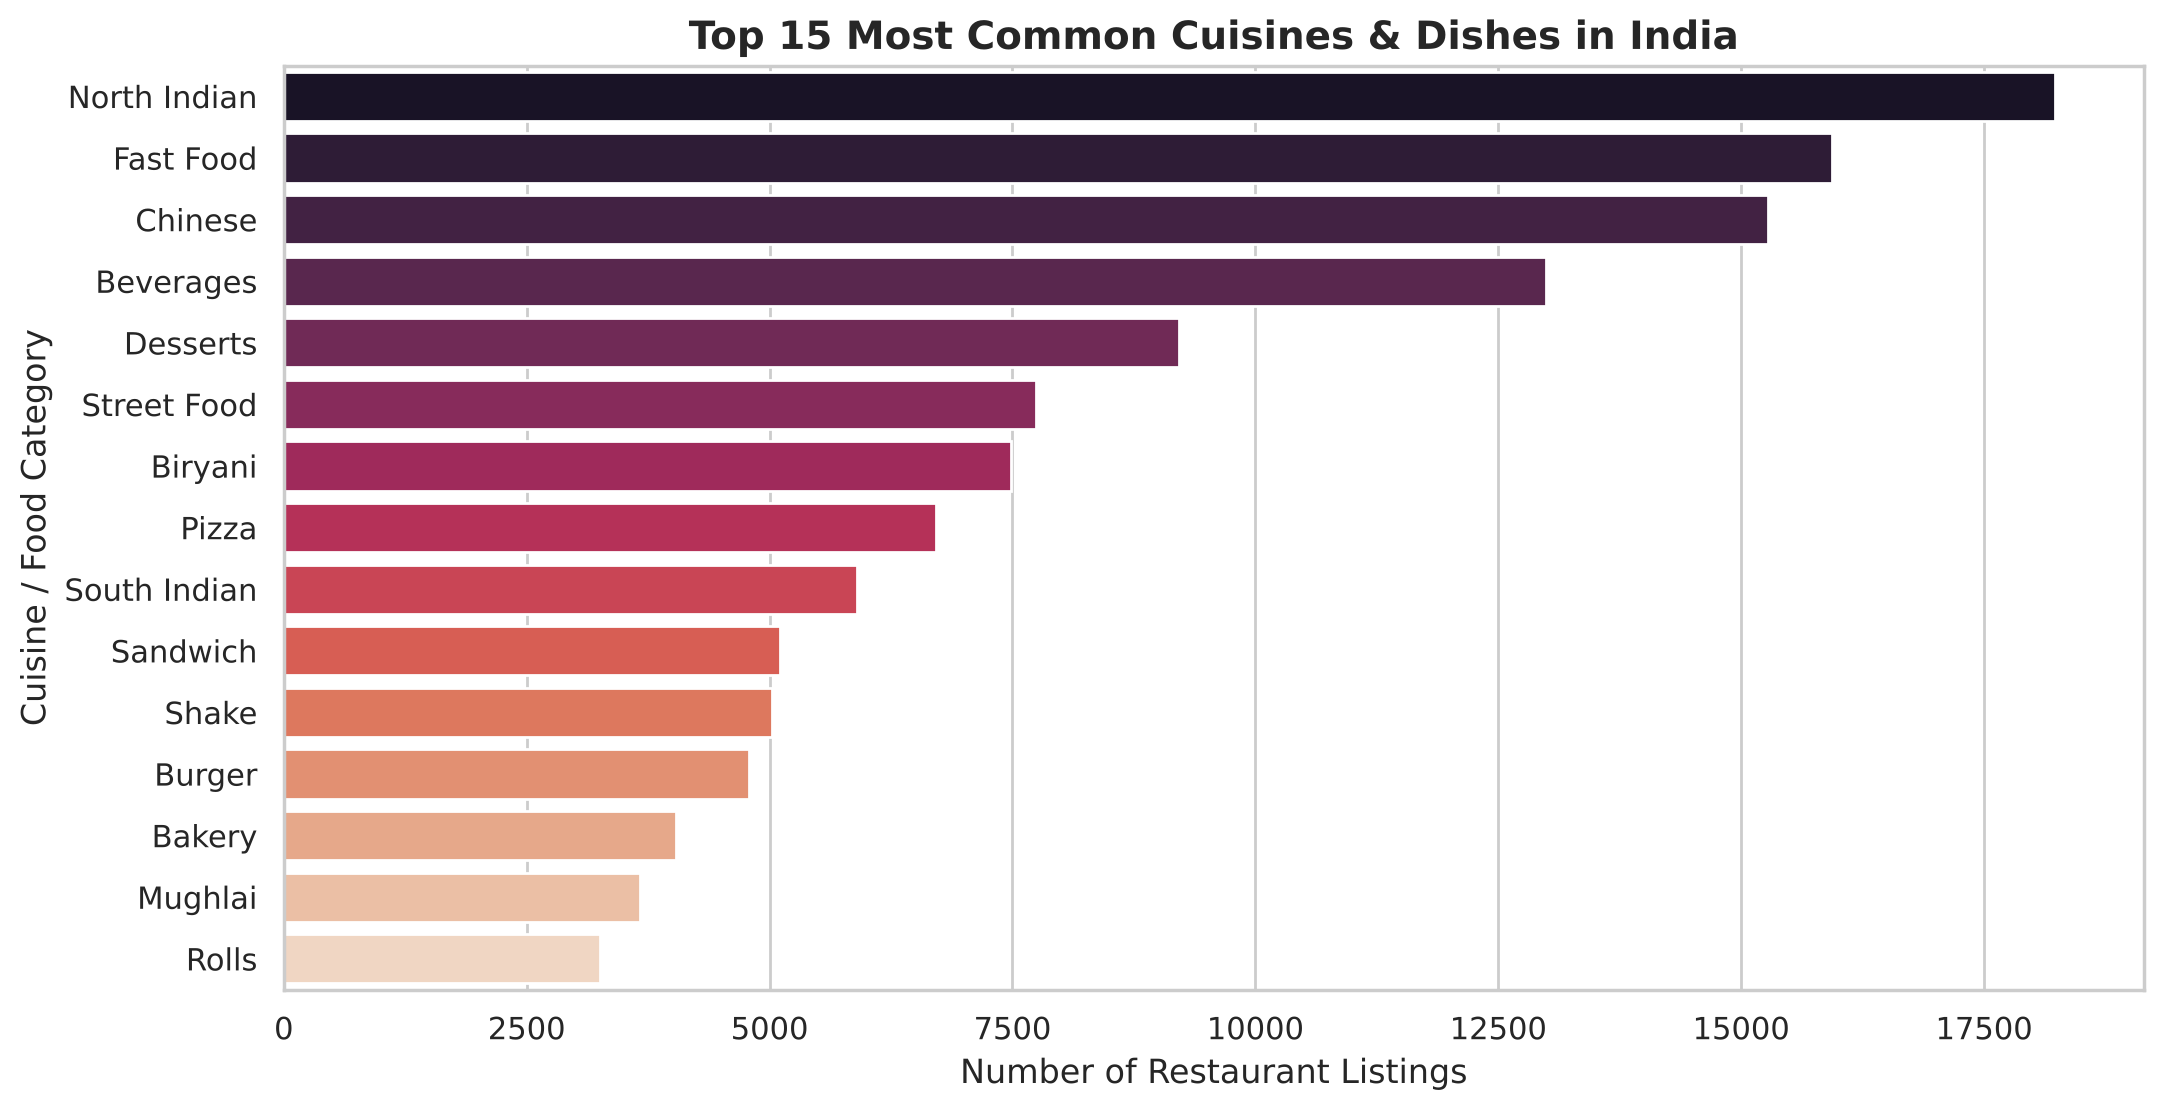

In [6]:
from collections import Counter

cuisines_list = []
for c_str in df["Cuisine"].dropna():
    cuisines_list.extend([c.strip() for c in c_str.split(",") if c.strip()])

cuisine_counts = pd.Series(Counter(cuisines_list)).sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index, hue=cuisine_counts.index, palette="rocket", legend=False)
plt.title("Top 15 Most Common Cuisines & Dishes in India", fontsize=14, weight="bold")
plt.xlabel("Number of Restaurant Listings")
plt.ylabel("Cuisine / Food Category")
plt.show()